# NASA Exoplanet Archive Analysis

**Author:** Nur Azreik  
**University:** University of Göttingen  
**Course:** Visualization  
**Program:** B.Sc. Applied Computer Science

-------------------------------------------------------------------------------------------------------------------------------------------------------------------

## 1. Imports

**Imports**

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import plotly.express as px
import plotly.graph_objects as go

from plotly.subplots import make_subplots

**Import Raw Data**

In [2]:
data = pd.read_csv("../data/data_exoplanets/exoplanets.csv", sep=';')

print(f"Rows: {len(data):,}")
print(f"Columns: {data.shape[1]}")
print(data.columns.tolist())

Rows: 6,316
Columns: 19
['pl_name', 'hostname', 'discoverymethod', 'disc_year', 'disc_facility', 'pl_orbper', 'pl_orbsmax', 'pl_orbeccen', 'pl_rade', 'pl_bmasse', 'pl_dens', 'pl_eqt', 'st_spectype', 'st_teff', 'st_rad', 'st_mass', 'sy_dist', 'glat', 'glon']


## 2. Methods, Facilities and Timeline

### Data Breakdown

**Prepare Data**

In [3]:
# Keep only discoveries with a known facility
facility_data = data.dropna(subset=['disc_facility']).copy()

**Breakdown**

In [4]:
# Display labels for aggregate archive categories
aggregate_display_names = {
    'Multiple Observatories':
        'Multiple Observatories (aggregate)',

    'Multiple Facilities':
        'Multiple Facilities (aggregate)'
}

# Keep every unique method-facility combination
method_facility_pairs = (
    facility_data[
        ['discoverymethod', 'disc_facility']
    ]
    .dropna()
    .drop_duplicates()
    .rename(columns={
        'discoverymethod': 'Discovery_Method',
        'disc_facility': 'Facility'
    })
)

# Mark aggregate categories
method_facility_pairs['Facility'] = (
    method_facility_pairs['Facility']
    .replace(aggregate_display_names)
)

# Combine all facilities belonging to each method
method_facilities = (
    method_facility_pairs
    .groupby(
        'Discovery_Method',
        as_index=False
    )
    .agg(
        Facility_Count=(
            'Facility',
            'nunique'
        ),
        Facilities=(
            'Facility',
            lambda facilities: ', '.join(
                sorted(facilities.unique())
            )
        )
    )
    .sort_values(
        by=[
            'Facility_Count',
            'Discovery_Method'
        ],
        ascending=[
            False,
            True
        ]
    )
    .reset_index(drop=True)
)

method_facilities

,Discovery_Method,Facility_Count,Facilities
0,Transit,36,"Acton Sky Portal Observatory, Anglo-Australian..."
1,Radial Velocity,30,"Anglo-Australian Telescope, Apache Point Obser..."
2,Imaging,21,"Apache Point Observatory, Cerro Tololo Inter-A..."
3,Microlensing,7,"European Space Agency (ESA) Gaia Satellite, K2..."
4,Eclipse Timing Variations,6,"Kepler, Leoncito Astronomical Complex, Multipl..."
5,Pulsar Timing,5,"Arecibo Observatory, Hubble Space Telescope, M..."
6,Transit Timing Variations,4,"KOINet, Kepler, Multiple Observatories (aggreg..."
7,Astrometry,3,"European Space Agency (ESA) Gaia Satellite, Pa..."
8,Pulsation Timing Variations,2,"Kepler, Multiple Observatories (aggregate)"
9,Disk Kinematics,1,Atacama Large Millimeter Array (ALMA)


**Percentage of Discovery Breakdown by Facility** 

In [5]:
# Count exoplanets discovered by each facility
counts = facility_data['disc_facility'].value_counts()

percentages = (facility_data['disc_facility'].value_counts(normalize=True).mul(100).round(2).astype(str) + ' %')

# Concatenate into 1 df
facility_breakdown = pd.concat([counts, percentages], axis=1, keys=['Exoplanets_Discovered', 'Percentage_of_Total (%)'])

# 
facility_breakdown = facility_breakdown.reset_index()
facility_breakdown.rename(columns={'disc_facility': 'Facility'}, inplace=True)


known_facilities = facility_data['disc_facility'].nunique()
missing_facilities = data['disc_facility'].isna().sum()

print(f"Total Exoplanets in Dataset: {len(data)}")
print(f"Exoplanets with Known Facility: {len(facility_data)}")
print(f"Known Discovery Facilities: {known_facilities}")
print(f"Missing Facility Values: {missing_facilities}")

Total Exoplanets in Dataset: 6316
Exoplanets with Known Facility: 6311
Known Discovery Facilities: 73
Missing Facility Values: 5


**Method Distribution Within Each Facility**

In [6]:
# Group by facility and count discoveries per method
method_counts = (
    facility_data
    .groupby('disc_facility')['discoverymethod']
    .value_counts()
    .rename('Exoplanets_Discovered')
)

method_percentages = (
    facility_data
    .groupby('disc_facility')['discoverymethod']
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
    .astype(str) + ' %'
)
method_percentages = method_percentages.rename('Percentage_of_Facility_Total')

# Combine both metrics
facility_method_breakdown = pd.concat([method_counts, method_percentages], axis=1).reset_index()

# Rename columns
facility_method_breakdown.rename(columns={
    'disc_facility': 'Facility', 
    'discoverymethod': 'Method'
}, inplace=True)

### Chart 1 - Stacked Horizontal Bar Chart

**Setup**

In [7]:
# Count discoveries made by every facility
facility_counts = (
    facility_data['disc_facility']
    .value_counts()
)

# Facilities responsible for at least 1% of discoveries
threshold = len(facility_data) * 0.01

major_facilities = (
    facility_counts[
        facility_counts >= threshold
    ]
    .index
    .tolist()
)

# Clearly mark aggregate archive categories
facility_display_names = {
    'Multiple Observatories':
        'Multiple Observatories (aggregate)',

    'Multiple Facilities':
        'Multiple Facilities (aggregate)'
}

chart1_data = facility_data[
    [
        'pl_name',
        'discoverymethod',
        'disc_facility'
    ]
].copy()

# Display-friendly facility names
chart1_data['facility_display'] = (
    chart1_data['disc_facility']
    .replace(facility_display_names)
)

# Keep major facilities separate
chart1_data['facility_group'] = np.where(
    chart1_data['disc_facility'].isin(
        major_facilities
    ),
    chart1_data['facility_display'],
    'Smaller facilities (<1% each)'
)

**Format Facility Lists for Hover Information**

In [8]:
# Format long facility lists for Plotly hover
def format_facility_list(facilities, names_per_line=3):

    names = sorted(
        facilities.dropna().unique()
    )

    lines = [
        ', '.join(
            names[index:index + names_per_line]
        )
        for index in range(
            0,
            len(names),
            names_per_line
        )
    ]

    return '<br>'.join(lines)

**Calculate Method–Facility Shares**

In [9]:
# Count discoveries and retain their facility names
method_facility_counts = (
    chart1_data
    .groupby(
        [
            'discoverymethod',
            'facility_group'
        ],
        as_index=False
    )
    .agg(
        Exoplanets_Discovered=(
            'disc_facility',
            'size'
        ),

        Facility_Count=(
            'facility_display',
            'nunique'
        ),

        Facilities=(
            'facility_display',
            format_facility_list
        )
    )
)

# Total number of discoveries for every method
method_totals = (
    method_facility_counts
    .groupby('discoverymethod')[
        'Exoplanets_Discovered'
    ]
    .transform('sum')
)

# Percentage within every method
method_facility_counts[
    'Percentage_of_Method (%)'
] = (
    method_facility_counts[
        'Exoplanets_Discovered'
    ]
    / method_totals
    * 100
)

# Control the legend order
facility_order = [
    facility_display_names.get(
        facility,
        facility
    )
    for facility in major_facilities
]

facility_order.append(
    'Smaller facilities (<1% each)'
)

**Plotting**

In [10]:
fig = px.bar(
    method_facility_counts,

    y='discoverymethod',
    x='Percentage_of_Method (%)',
    color='facility_group',

    orientation='h',

    category_orders={
        'facility_group': facility_order
    },

    custom_data=[
        'Exoplanets_Discovered',
        'Percentage_of_Method (%)',
        'Facility_Count',
        'Facilities'
    ],

    title=(
        'Exoplanet Discoveries: Facility Breakdown per Method'
        '<br><sup>'
        'Major facilities are shown separately. '
        'Hover over “Smaller facilities” to see their names.'
        '</sup>'
    ),

    color_discrete_sequence=(
        px.colors.qualitative.Alphabet
    )
)

fig.update_traces(
    hovertemplate=(
        '<b>%{y}</b><br>'
        'Group: %{fullData.name}<br>'
        'Discoveries: %{customdata[0]:,}<br>'
        'Share within method: %{customdata[1]:.2f}%<br>'
        'Number of facility categories: %{customdata[2]}<br>'
        '<br><b>Facilities</b><br>'
        '%{customdata[3]}'
        '<extra></extra>'
    )
)

fig.update_layout(
    xaxis_title=(
        'Percentage of Discoveries '
        'Within Method (%)'
    ),

    yaxis_title='Discovery Method',
    legend_title='Discovery Facility',

    barmode='stack',
    height=800,

    margin=dict(
        l=200,
        r=20,
        t=100,
        b=60
    )
)

fig.update_xaxes(
    range=[0, 100],

    tickmode='array',

    tickvals=[
        0,
        20,
        40,
        60,
        80,
        100
    ],

    ticktext=[
        '0%',
        '20%',
        '40%',
        '60%',
        '80%',
        '100%'
    ]
)

fig.show()

### Chart 2 - Interactive Line Chart

**Setup**

In [11]:
# Count discoveries by year and method
yearly_methods = data.groupby(['disc_year', 'discoverymethod']).size().reset_index(name='count')

# Create Matrix fill NaNs
pivot_df = yearly_methods.pivot(index='disc_year', columns='discoverymethod', values='count').fillna(0)

# Melt for plotly
timeline_data = pivot_df.reset_index().melt(
    id_vars='disc_year',
    value_vars=pivot_df.columns,
    var_name='discoverymethod',
    value_name='Exoplanets_Discovered'
)

# Transform counts while preserving zero-discovery years
timeline_data['Plot_Value'] = np.log10(timeline_data['Exoplanets_Discovered'] + 1)

**Plotting**

In [12]:
fig = px.line(
    timeline_data,
    x='disc_year',
    y='Plot_Value',
    color='discoverymethod',

    custom_data=[
        'Exoplanets_Discovered'
    ],

    title=(
        'Exoplanet Discoveries by Year and Method'
        '<br><sup>'
        'The vertical axis uses log10(count + 1), '
        'allowing zero-discovery years to remain visible.'
        '</sup>'
    ),

    labels={
        'disc_year': 'Discovery Year',
        'Plot_Value': 'Exoplanets Discovered per Year',
        'discoverymethod': 'Discovery Method'
    }
)

fig.update_traces(
    mode='lines+markers',

    hovertemplate=(
        'Discovery Year: %{x:.0f}<br>'
        'Exoplanets Discovered: %{customdata[0]:,.0f}'
        '<extra>%{fullData.name}</extra>'
    )
)

fig.update_layout(
    xaxis_title='Discovery Year',
    yaxis_title='Exoplanets Discovered per Year',
    legend_title='Discovery Method',
    height=700
)

# Display the transformed axis using the original count values
actual_tick_values = np.array([
    0,
    1,
    10,
    100,
    1000
])

fig.update_yaxes(
    tickmode='array',
    tickvals=np.log10(actual_tick_values + 1),
    ticktext=[
        '0',
        '1',
        '10',
        '100',
        '1,000'
    ],
    range=[
        0,
        np.log10(
            timeline_data['Exoplanets_Discovered'].max() + 1
        ) * 1.05
    ]
)

fig.show()

*2026 represents a partial year in the dataset.*

### Chart 3 - Facility Method Coverage Matrix

**Facility Method Diversity**

In [13]:
# Group by facility and count unique methods
facility_method_counts = (
    facility_data
    .groupby('disc_facility')['discoverymethod']
    .nunique()
    .reset_index()
)

facility_method_counts.columns = [
    'Facility',
    'Unique_Methods_Count'
]

facility_method_counts = facility_method_counts.sort_values(
    by='Unique_Methods_Count',
    ascending=False
)

# These are aggregate archive categories, not individual facilities
aggregate_facilities = [
    'Multiple Observatories',
    'Multiple Facilities'
]

individual_facility_method_counts = facility_method_counts[
    ~facility_method_counts['Facility'].isin(aggregate_facilities)
]

aggregate_facility_method_counts = facility_method_counts[
    facility_method_counts['Facility'].isin(aggregate_facilities)
]

print("Individually named facilities sorted by method diversity:")
print(individual_facility_method_counts.head(15))

print("\nAggregate archive categories:")
print(aggregate_facility_method_counts)

Individually named facilities sorted by method diversity:
                                        Facility  Unique_Methods_Count
27                                        Kepler                     5
11    European Space Agency (ESA) Gaia Satellite                     4
46                           Paranal Observatory                     4
13                            Gemini Observatory                     3
18                        Hubble Space Telescope                     3
37                         Mauna Kea Observatory                     3
8        Cerro Tololo Inter-American Observatory                     3
52                       Spitzer Space Telescope                     2
65                        W. M. Keck Observatory                     2
61  Transiting Exoplanet Survey Satellite (TESS)                     2
54                                     SuperWASP                     2
53                              Subaru Telescope                     2
2                  

**Method Adoption Across Facilities**

In [14]:
# Count
method_adoption = (facility_data.groupby('discoverymethod')['disc_facility'].nunique().reset_index())
method_adoption.columns = ['Discovery Method', 'Facility Count']

# unique facilities
total_facilities = facility_data['disc_facility'].nunique()

# Calculate the percentage
method_adoption['Percentage of Facilities (%)'] = (method_adoption['Facility Count'] / total_facilities) * 100

# Sort
method_adoption = method_adoption.sort_values(by='Facility Count', ascending=False)

# Format
method_adoption['Percentage of Facilities (%)'] = method_adoption['Percentage of Facilities (%)'].round(2).astype(str) + ' %'

print(f"Total Unique Facilities: {total_facilities}")
print("Method Adoption Rate Across Facilities:")
print(method_adoption.to_string(index=False))

Total Unique Facilities: 73
Method Adoption Rate Across Facilities:
             Discovery Method  Facility Count Percentage of Facilities (%)
                      Transit              36                      49.32 %
              Radial Velocity              30                       41.1 %
                      Imaging              21                      28.77 %
                 Microlensing               7                       9.59 %
    Eclipse Timing Variations               6                       8.22 %
                Pulsar Timing               5                       6.85 %
    Transit Timing Variations               4                       5.48 %
                   Astrometry               3                       4.11 %
  Pulsation Timing Variations               2                       2.74 %
              Disk Kinematics               1                       1.37 %
Orbital Brightness Modulation               1                       1.37 %


**Setup**

In [15]:
# Create a Matrix
matrix = pd.crosstab(facility_data['disc_facility'], facility_data['discoverymethod'])

# Sort columns (methods)
method_order = facility_data.groupby('discoverymethod')['disc_facility'].nunique().sort_values(ascending=False).index

# Sort rows (facilities)
facility_order = facility_data.groupby('disc_facility')['discoverymethod'].nunique().sort_values(ascending=False).index

# Apply sorting
matrix_sorted = matrix.loc[facility_order, method_order]

matrix_sorted = matrix_sorted.rename(
    index={
        'Multiple Observatories':
            'Multiple Observatories (aggregate)',
        'Multiple Facilities':
            'Multiple Facilities (aggregate)'
    }
)

matrix_categorical = matrix_sorted.copy()
for i, col in enumerate(matrix_categorical.columns):
    # If discoveries > 0, assign the method's unique index (i + 1)
    matrix_categorical[col] = matrix_categorical[col].apply(lambda x: i + 1 if x > 0 else 0)


**Plotting**

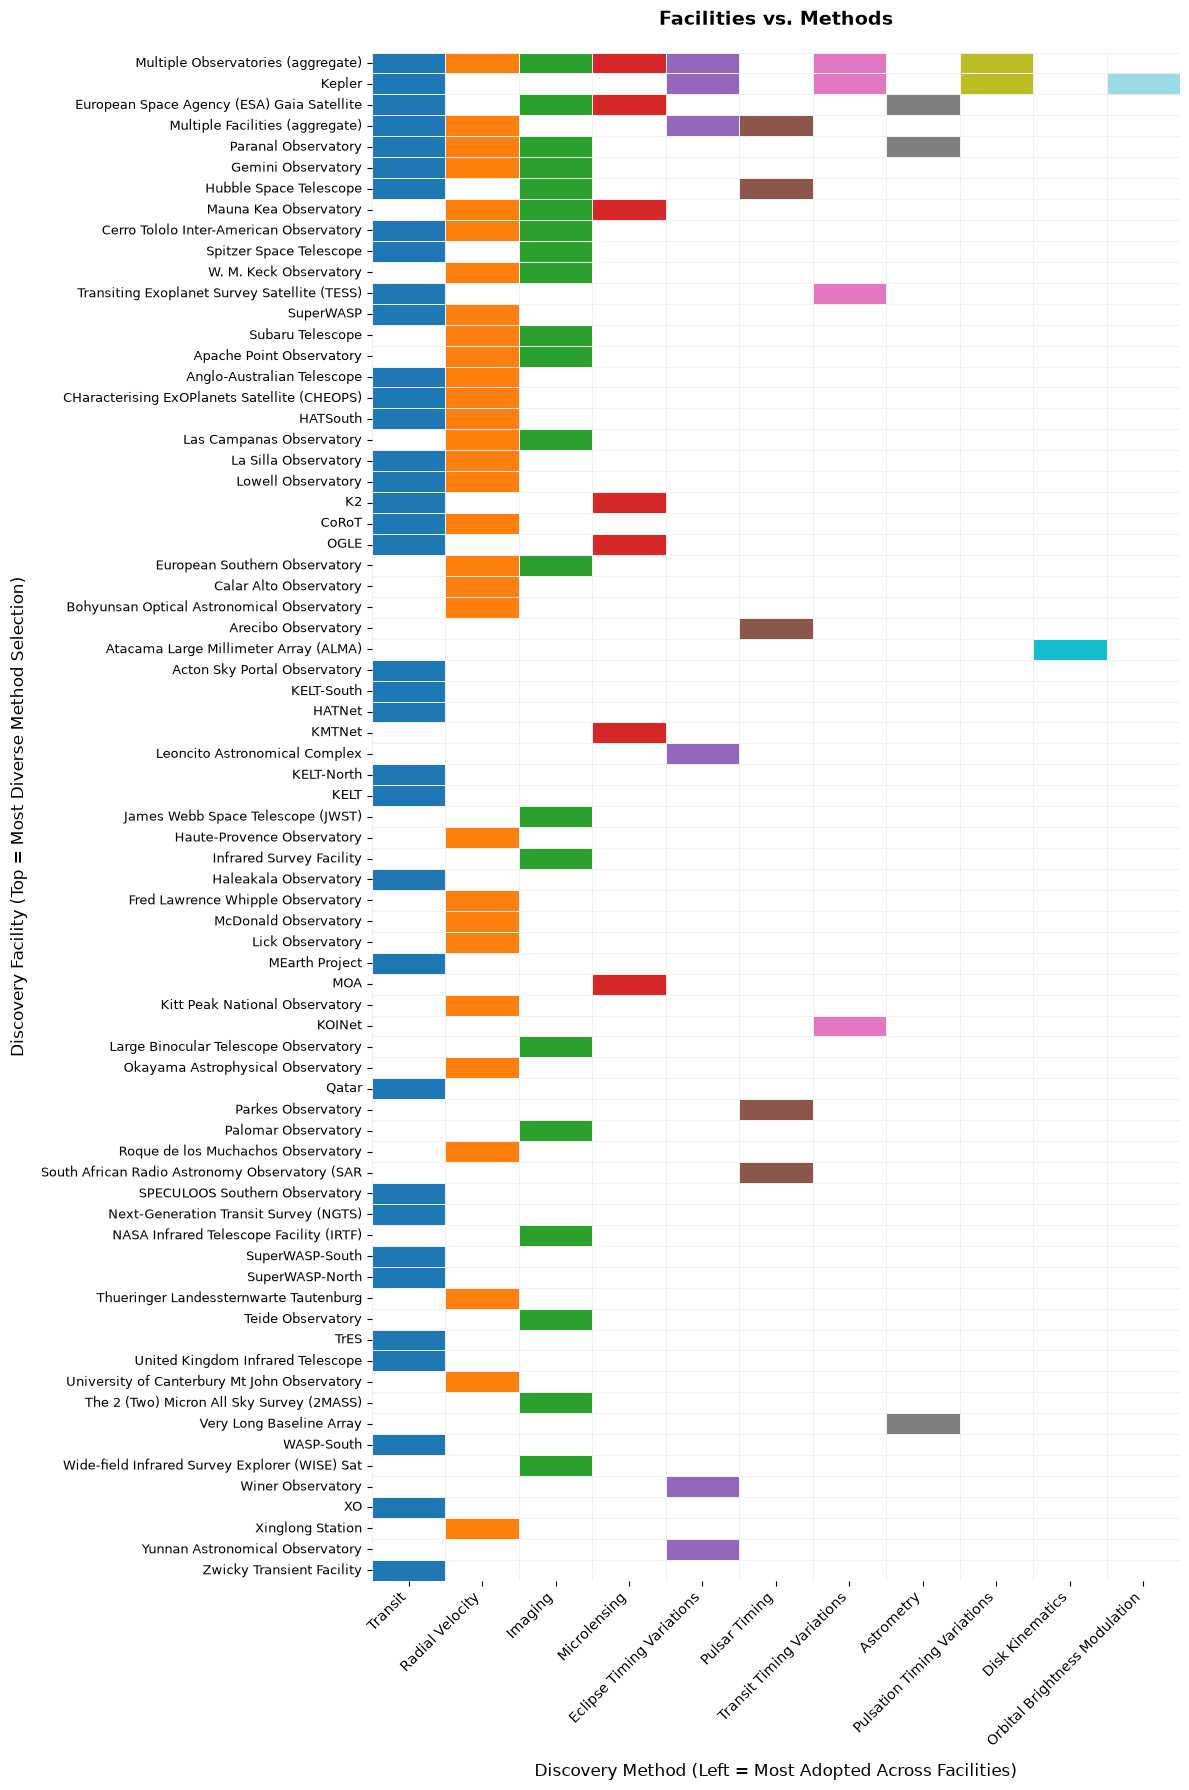

In [16]:
# Plotting
plt.figure(figsize=(12, 18))
ax = sns.heatmap(
    matrix_categorical,
    mask=(matrix_sorted == 0),
    cmap='tab20', 
    linewidths=0.5,
    linecolor='#f0f0f0',
    cbar=False
)

# Clean up
plt.title('Facilities vs. Methods', fontsize=14, pad=20, weight='bold')
plt.xlabel('Discovery Method (Left = Most Adopted Across Facilities)', fontsize=12, labelpad=10)
plt.ylabel('Discovery Facility (Top = Most Diverse Method Selection)', fontsize=12, labelpad=10)

# Rotate
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.yticks(fontsize=9)

plt.tight_layout()
plt.show()

### Chart 4 - Horizontal Bar Chart

**Setup**

In [17]:
# Calculate the threshold (1% of total discoveries)
total_discoveries = len(facility_data)
threshold = 0.01 * total_discoveries

# Get counts and aggregate Other
facility_counts = facility_data['disc_facility'].value_counts()
major_facilities = facility_counts[facility_counts >= threshold]
others_count = facility_counts[facility_counts < threshold].sum()

# Prepare the DataFrame
plot_data = major_facilities.reset_index()
plot_data.columns = ['disc_facility', 'count']

# Other < 1%
other_df = pd.DataFrame({'disc_facility': ['Other (<1%)'], 'count': [others_count]})
plot_data = pd.concat([plot_data, other_df], ignore_index=True)

# Calculate Percentage
plot_data['percentage'] = (plot_data['count'] / total_discoveries) * 100
plot_data['display_label'] = plot_data.apply(
    lambda x: f"{x['count']} ({x['percentage']:.1f}%)", axis=1
)


**Plotting**

In [18]:
# Plot
fig = px.bar(
    plot_data,
    x='count',
    y='disc_facility',
    orientation='h',
    title="Exoplanet Discovery Facilities (Major Facilities vs Other)",
    text='display_label', 
    labels={'count': 'Number of Discoveries', 'disc_facility': 'Facility'},
    color='count',
    color_continuous_scale='Blues'
)

# Clean up layout
fig.update_layout(
    margin=dict(r=100), 
    yaxis={'categoryorder': 'total ascending'}, 
    plot_bgcolor='white',
    xaxis=dict(gridcolor='lightgrey'),
    showlegend=False
)

fig.update_traces(
    texttemplate='%{text}', 
    textposition='outside'
)

fig.show()

## 3. Discoveries in galactic latitude and longitude

### Chart 1 - Interactive Mollweide Chart

**Checking Boundaries**

In [19]:
# Check Boundaries
print(data[['glon', 'glat']].describe())

              glon        glat
count  6289.000000  6289.00000
mean    137.051862     6.04297
std      97.268914    29.51060
min       0.029010   -88.32478
25%      74.174440    -3.11860
50%      80.466220    11.71140
75%     213.131550    17.79385
max     359.996270    88.99898


**Setup and Lable**

In [20]:
# Drop NaNs and copy
map_data = data.dropna(
    subset=['glon', 'glat', 'disc_facility']
).copy()

# Reuse top 12 facilities from Section 2
top_12 = facility_breakdown.head(12).copy()

top_12_facilities = top_12['Facility'].tolist()
categories = top_12_facilities + ['Other']

# Assign discovery to facility
map_data['facility_group'] = np.where(
    map_data['disc_facility'].isin(top_12_facilities),
    map_data['disc_facility'],
    'Other'
)

# Shorter display names
display_names = {
    'Transiting Exoplanet Survey Satellite (TESS)': 'TESS',
    'Haute-Provence Observatory': 'Haute-Provence Obs.',
    'W. M. Keck Observatory': 'W. M. Keck Obs.',
    'La Silla Observatory': 'La Silla Obs.'
}

# Count only discoveries shown on the map
map_counts = map_data['disc_facility'].value_counts()
map_total = len(map_data)

# Legend labels
legend_labels = {
    facility: (
        f"{display_names.get(facility, facility)} — "
        f"{map_counts[facility]:,} planets "
        f"({map_counts[facility] / map_total * 100:.2f} %)"
    )
    for facility in top_12_facilities
}

# Other facilities
other_planet_count = (map_data['facility_group'] == 'Other').sum()
other_percentage = other_planet_count / map_total * 100

other_facility_count = (
    map_data.loc[
        map_data['facility_group'] == 'Other',
        'disc_facility'
    ].nunique()
)

legend_labels['Other'] = (
    f"Other — {other_planet_count:,} mapped planets "
    f"({other_percentage:.2f} % combined)<br>"
    f"{other_facility_count} facilities"
)

**Coordinates and Colours**

In [21]:
# Transform longitude from 0°-360° to -180°-180° and reverse direction for the sky map
map_data['plot_longitude'] = -(
    (map_data['glon'] + 180) % 360 - 180
)

# Assign colours to category
colour_map = dict(zip(
    categories,
    px.colors.qualitative.Dark24[:len(categories)]
))

**Interactive Map**

In [22]:
# Create Figure
fig = go.Figure()

# Get exoplanets for each facility
for position, facility in enumerate(categories):
    subset = map_data[
        map_data['facility_group'] == facility
    ]
    # Creates clickable squared legend for each facility
    fig.add_trace(
        go.Scattergeo(
            # setup
            lon=[None],
            lat=[None],
            mode='markers',
            name=legend_labels[facility],
            legendgroup=facility,
            legendrank=position,
            # style
            marker=dict(
                size=12,
                symbol='square',
                color=colour_map[facility],
                line=dict(
                    color='black',
                    width=1
                )
            ),

            hoverinfo='skip',
            showlegend=True
        )
    )

    # Create the dots on the map
    fig.add_trace(
        go.Scattergeo(
            # setup
            lon=subset['plot_longitude'],
            lat=subset['glat'],
            mode='markers',
            legendgroup=facility,
            legendrank=position,
            showlegend=False,
            
            # style
            marker=dict(
                size=4,
                symbol='circle',
                color=colour_map[facility],
                opacity=0.65,
                line=dict(width=0)
            ),
            # adding the data
            customdata=np.column_stack([
                subset['pl_name'],
                subset['disc_facility'],
                subset['glon'],
                subset['glat'],
                subset['discoverymethod']
            ]),
            # hover data
            hovertemplate=(
                "<b>%{customdata[0]}</b><br>"
                "Facility: %{customdata[1]}<br>"
                "Galactic longitude: %{customdata[2]:.2f}°<br>"
                "Galactic latitude: %{customdata[3]:.2f}°<br>"
                "Discovery Method: %{customdata[4]}"
                "<extra></extra>"
            )
        )
    )

**Layout and Display**

In [23]:
# Create Display Figure
fig.update_layout(
    # Title
    title=dict(
        text=(
            "Exoplanet Discoveries Distributed by Galactic Latitude and Longitude"
            "<br>"
            "<sup>Click a coloured square to hide or show a facility. "
            "Double-click to show only one facility.</sup>"
        ),
        x=0.36,
        font=dict(size=17)
    ),
    # Size
    geo=dict(
        domain=dict(
            x=[0.00, 0.68],
            y=[0.05, 0.93]
        ),

        projection=dict(type='mollweide'),

        # all black
        bgcolor='black',

        showland=True,
        landcolor='black',

        showocean=True,
        oceancolor='black',

        showlakes=True,
        lakecolor='black',

        showcountries=False,
        showcoastlines=False,
        showrivers=False,

        showframe=True,
        framecolor='gray',
        framewidth=1,
        # lines
        lonaxis=dict(
            showgrid=True,
            gridwidth=0.5,
            gridcolor='gray',
            dtick=30
        ),
        lataxis=dict(
            showgrid=True,
            gridwidth=0.5,
            gridcolor='gray',
            dtick=30
        )
    ),
    # Text
    legend=dict(
        title="Discovery facility",

        x=0.70,
        y=0.90,
        xanchor='left',
        yanchor='top',

        font=dict(size=9),
        title_font=dict(size=11),

        groupclick='togglegroup',
        itemdoubleclick='toggleothers',
        itemsizing='constant',
        tracegroupgap=2
    ),
    # Size
    width=1400,
    height=700,

    margin=dict(
        l=25,
        r=25,
        t=90,
        b=25
    )
)

fig.show()

### What patterns are there and how are they related to the discovering facilities?

By isolating the different discovering facilities, we can see that the discoveries are not distributed evenly across the sky. Kepler shows the most concentrated pattern, with its discoveries limited to approximately 5.84° to 21.14° in galactic latitude and 68.23° to 84.38° in galactic longitude. In contrast, TESS, W. M. Keck Observatory, and SuperWASP show wider sky coverage. The archive’s “Multiple Observatories” category is also widely distributed, as expected because it combines discoveries from several sites. K2 and HATSouth form several separate observing regions rather than one compact field.

OGLE and KMTNet show a different pattern, with most discoveries concentrated close to the galactic equator. OGLE ranges from approximately −5.42° to 4.41° in latitude and KMTNet from −6.16° to 4.16°. Their longitude values appear to span almost 0° to 360° because their clusters cross the 0°/360° boundary, not because they cover the entire sky. La Silla Observatory, Haute-Provence Observatory, and HATNet also have wide but uneven distributions.

The remaining 61 archive facility categories account for 638 mapped planets, representing about 10.14% of the 6,289 discoveries shown on the map. Overall, the patterns are strongly related to the regions observed by each facility: facilities targeting specific fields create compact or separate clusters, while facilities with wider sky coverage produce more dispersed distributions.

## 4. Discovered Planets, Radius and Distance

### Chart 1 - Interactive Scatter Plot

**Prepare Data**

In [24]:
# Drop missing values
radius_distance_data = data.dropna(subset=['pl_rade', 'sy_dist', 'discoverymethod']).copy()

# Radius Range
print(f"Min Radius: ", (radius_distance_data['pl_rade'].min()))
print(f"Max Radius: ", (radius_distance_data['pl_rade'].max()))

# Distance Range
print("Minimum distance:", radius_distance_data['sy_dist'].min())
print("Maximum distance:", radius_distance_data['sy_dist'].max())

Min Radius:  0.3098
Max Radius:  77.3421
Minimum distance: 1.30119
Maximum distance: 8500.0


**Radius Bins**

In [25]:
# Create Bins
radius_bins = [
    0,
    1,
    2,
    4,
    8,
    16,
    float('inf')
]

# Lable
radius_labels = [
    '< 1',
    '1–2',
    '2–4',
    '4–8',
    '8–16',
    '≥ 16'
]

# Cut
radius_distance_data['radius_group'] = pd.cut(
    radius_distance_data['pl_rade'],
    bins=radius_bins,
    labels=radius_labels,
    right=False
)

radius_distance_data['radius_group'].value_counts().sort_index()

radius_group
< 1      229
1–2     1529
2–4     2073
4–8      444
8–16    1777
≥ 16     161
Name: count, dtype: int64

**Distance Bins**

In [26]:
# Create Bin
distance_bins = [
    0,
    10,
    100,
    1000,
    float('inf')
]

# Lable
distance_labels = [
    '< 10',
    '10–100',
    '100–1,000',
    '≥ 1,000'
]

# Cut
radius_distance_data['distance_group'] = pd.cut(
    radius_distance_data['sy_dist'],
    bins=distance_bins,
    labels=distance_labels,
    right=False
)

# Get Data
radius_distance_data['distance_group'].value_counts().sort_index()

distance_group
< 10          120
10–100       1400
100–1,000    3589
≥ 1,000      1104
Name: count, dtype: int64

**Create Figure and Plot**

In [27]:
# Interactive scatter plot
fig = px.scatter(
    radius_distance_data,
    x='sy_dist',
    y='pl_rade',
    color='discoverymethod',

    hover_name='pl_name',

    hover_data={
        'sy_dist': ':.2f',
        'pl_rade': ':.2f',
        'radius_group': True,
        'distance_group': True,
        'discoverymethod': True,
        'disc_facility': True
    },

    log_x=True,
    log_y=True,

    labels={
    'sy_dist': 'Distance (parsecs)',
    'pl_rade': 'Planet Radius (Earth radii)',
    'discoverymethod': 'Discovery Method',
    'disc_facility': 'Discovery Facility'
    },

    title='Distribution of Exoplanets by Planet Radius and Distance'
)


# Point appearance
fig.update_traces(
    marker=dict(
        size=6,
        opacity=0.6
    )
)

# Cleaner logarithmic y-axis
fig.update_yaxes(
    tickmode='array',
    tickvals=[0.3, 0.5, 1, 2, 5, 10, 20, 50, 100],
    ticktext=['0.3', '0.5', '1', '2', '5', '10', '20', '50', '100']
)

# Cleaner logarithmic x-axis
fig.update_xaxes(
    tickmode='array',
    tickvals=[1, 10, 100, 1000, 10000],
    ticktext=['1', '10', '100', '1,000', '10,000']
)

fig.update_layout(
    width=1200,
    height=1000
)

fig.show()

### Chart 2 - Interactive Multiple Scatter Plots

In [28]:
# Drop NaNs and Copy
facility_radius_distance = radius_distance_data.dropna(
    subset=['disc_facility']
).copy()

# Count discoveries per facility
facility_coverage = (facility_radius_distance['disc_facility'].value_counts().reset_index())

# Columns
facility_coverage.columns = [
    'Facility',
    'Exoplanets_Discovered'
]

# Percentage
facility_coverage['Percentage'] = (
    facility_coverage['Exoplanets_Discovered']
    / facility_coverage['Exoplanets_Discovered'].sum()
    * 100
)

# Cumulative percentage
facility_coverage['Cumulative_Percentage'] = (
    facility_coverage['Percentage'].cumsum()
)

facility_coverage.head(20)



,Facility,Exoplanets_Discovered,Percentage,Cumulative_Percentage
0,Kepler,2765,44.503460,44.503460
1,Transiting Exoplanet Survey Satellite (TESS),894,14.389184,58.892644
2,K2,548,8.820216,67.712860
3,Multiple Observatories,343,5.520682,73.233543
4,La Silla Observatory,288,4.635442,77.868984
5,W. M. Keck Observatory,184,2.961532,80.830517
6,KMTNet,139,2.237244,83.067761
7,SuperWASP,117,1.883148,84.950909
8,OGLE,109,1.754386,86.705295
9,HATSouth,73,1.174956,87.880251


**Setup**

In [29]:
# Top 12 Facilities (90%)
selected_facilities = (
    facility_coverage
    .head(12)['Facility']
    .tolist()
)

# Group all remaining facilities as "Other"
facility_radius_distance['facility_group'] = np.where(
    facility_radius_distance['disc_facility'].isin(selected_facilities),
    facility_radius_distance['disc_facility'],
    'Other'
)

# Combine and Order
facility_order = selected_facilities + ['Other']

selected_facilities


['Kepler',
 'Transiting Exoplanet Survey Satellite (TESS)',
 'K2',
 'Multiple Observatories',
 'La Silla Observatory',
 'W. M. Keck Observatory',
 'KMTNet',
 'SuperWASP',
 'OGLE',
 'HATSouth',
 'Haute-Provence Observatory',
 'HATNet']

**Plotting**

In [30]:
# Create Figure
fig = px.scatter(
    facility_radius_distance,
    x='sy_dist',
    y='pl_rade',

    facet_col='facility_group',
    facet_col_wrap=4,

    category_orders={
        'facility_group': facility_order
    },

    hover_name='pl_name',

    hover_data={
        'sy_dist': ':.2f',
        'pl_rade': ':.2f',
        'discoverymethod': True,
        'facility_group': True
    },

    log_x=True,
    log_y=True,

    labels={
    'sy_dist': 'Distance (parsecs)',
    'pl_rade': 'Planet Radius (Earth radii)',
    'discoverymethod': 'Discovery Method',
    'facility_group': 'Discovery Facility'
    },

    title='Exoplanet Radius and Distance by Discovery Facility'
)


# Point appearance
fig.update_traces(
    marker=dict(
        size=4,
        opacity=0.6
    )
)


# Cleaner logarithmic y-axis
fig.update_yaxes(
    tickmode='array',
    tickvals=[0.3, 0.5, 1, 2, 5, 10, 20, 50, 100],
    ticktext=['0.3', '0.5', '1', '2', '5', '10', '20', '50', '100'],
    title_text=''
)


# Cleaner logarithmic x-axis
fig.update_xaxes(
    tickmode='array',
    tickvals=[1, 10, 100, 1000, 10000],
    ticktext=['1', '10', '100', '1,000', '10,000'],
    title_text=''
)


# Remove the variable prefix from facet titles
fig.for_each_annotation(
    lambda a: a.update(
        text=(
            a.text
            .replace('facility_group=', '')
            .replace('Discovery Facility=', '')
        )
    )
)

# Global x-axis title
fig.add_annotation(
    text='Distance (parsecs)',
    x=0.5,
    y=-0.06,
    xref='paper',
    yref='paper',
    showarrow=False,
    font=dict(size=16)
)


# Global y-axis title
fig.add_annotation(
    text='Planet Radius (Earth radii)',
    x=-0.06,
    y=0.5,
    xref='paper',
    yref='paper',
    showarrow=False,
    textangle=-90,
    font=dict(size=16)
)


# Layout
fig.update_layout(
    width=1400,
    height=1300,
    margin=dict(
        l=110,
        r=40,
        t=100,
        b=110
    )
)

fig.show()

## 5. Discovery Methods over Radii and Distance

### Data Breakdown

**Observed Data Ranges**

In [31]:
# Drop NaNs and Copy
method_limit_data = data[['discoverymethod', 'pl_rade', 'sy_dist']].dropna(
    subset=['discoverymethod']
).copy()

# non-positive values as missing
method_limit_data.loc[method_limit_data['pl_rade'] <= 0, 'pl_rade'] = np.nan
method_limit_data.loc[method_limit_data['sy_dist'] <= 0, 'sy_dist'] = np.nan

# Radius and distance ranges using their separately available values
method_ranges = (
    method_limit_data.groupby('discoverymethod').agg(
        Radius_Entries=('pl_rade', 'count'),
        Min_Radius=('pl_rade', 'min'),
        Max_Radius=('pl_rade', 'max'),
        Distance_Entries=('sy_dist', 'count'),
        Min_Distance=('sy_dist', 'min'),
        Max_Distance=('sy_dist', 'max')
    ).sort_values('Radius_Entries', ascending=False).reset_index()
)

method_ranges[['Min_Radius', 'Max_Radius', 'Min_Distance', 'Max_Distance']] = method_ranges[['Min_Radius', 'Max_Radius', 'Min_Distance', 'Max_Distance']].round(2)

method_ranges

,discoverymethod,Radius_Entries,Min_Radius,Max_Radius,Distance_Entries,Min_Distance,Max_Distance
0,Transit,4650,0.31,32.60,4624,6.87,8500.00
1,Radial Velocity,1158,0.64,15.58,1190,1.30,1539.71
2,Microlensing,281,1.09,14.30,279,505.00,8340.00
3,Imaging,93,10.47,87.21,90,10.10,230.01
4,Transit Timing Variations,38,0.37,14.10,39,9.72,1314.51
5,Eclipse Timing Variations,15,12.00,13.50,16,21.19,1188.54
6,Astrometry,6,11.90,13.30,6,6.26,73.64
7,Pulsar Timing,6,0.34,13.90,6,230.00,1200.00
8,Orbital Brightness Modulation,6,0.76,15.24,9,454.95,1672.94
9,Pulsation Timing Variations,2,12.40,13.10,2,1195.98,1382.89


### Chart 1 (Box Plot) - Method and Radius

**Setup**

In [32]:
# Drop NaNs and copy
radius_data = data.dropna(subset=['discoverymethod', 'pl_rade']).copy()

# Keep positive values
radius_data = radius_data[radius_data['pl_rade'] > 0]

# Count available radius entries for each method
radius_counts = radius_data['discoverymethod'].value_counts()

# Add counts to method labels
radius_data['method_label'] = radius_data['discoverymethod'].map(
    lambda method: f"{method} (n={radius_counts[method]:,})"
)

radius_method_order = [
    f"{method} (n={radius_counts[method]:,})"
    for method in radius_counts.index
]

**Plotting**

In [33]:
# Create figure
fig_radius = px.box(
    radius_data,
    x='pl_rade',
    y='method_label',

    category_orders={'method_label': radius_method_order},

    log_x=True,
    points=False,

    labels={
        'pl_rade': 'Planet Radius (Earth radii)',
        'method_label': 'Discovery Method'
    },

    title=(
        'Distribution of Planet Radius by Discovery Method'
        '<br><sup>Boxes represent the middle 50% of values; '
        'n shows available radius entries.</sup>'
    )
)

fig_radius.update_layout(
    width=1400,
    height=700
)

fig_radius.update_xaxes(
    type='log',
    tickmode='array',
    tickvals=[0.3, 0.5, 1, 2, 5, 10, 20, 50, 100],
    ticktext=['0.3', '0.5', '1', '2', '5', '10', '20', '50', '100']
)

fig_radius.update_yaxes(
    automargin=True
)

fig_radius.show()

### Chart 2 (Box Plot) - Method and Distance

**Setup**

In [34]:
# Drop NaNs and Copy
distance_data = data.dropna(subset=['discoverymethod', 'sy_dist']).copy()

# Keep positive values
distance_data = distance_data[distance_data['sy_dist'] > 0]

# Count available distance entries for each method
distance_counts = distance_data['discoverymethod'].value_counts()

# Add counts to method labels
distance_data['method_label'] = distance_data['discoverymethod'].map(
    lambda method: f"{method} (n={distance_counts[method]:,})"
)

distance_method_order = [
    f"{method} (n={distance_counts[method]:,})"
    for method in distance_counts.index
]

**Plotting**

In [35]:
# Create figure
fig_distance = px.box(
    distance_data,
    x='sy_dist',
    y='method_label',

    category_orders={'method_label': distance_method_order},

    log_x=True,
    points=False,

    labels={
        'sy_dist': 'System Distance (parsecs)',
        'method_label': 'Discovery Method'
    },

    title=(
        'Distribution of System Distance by Discovery Method'
        '<br><sup>Boxes represent the middle 50% of values; '
        'n shows available distance entries.</sup>'
    )
)

fig_distance.update_layout(
    width=1400,
    height=700
)

fig_distance.update_xaxes(
    type='log',
    tickmode='array',
    tickvals=[1, 10, 100, 1000, 10000],
    ticktext=['1', '10', '100', '1,000', '10,000']
)

fig_distance.update_yaxes(
    automargin=True
)

fig_distance.show()

## 6. List of Parameters Distribution

### Data Breakdown

In [36]:
# Parameters
distribution_columns = [
    'pl_orbper',
    'pl_orbsmax',
    'pl_rade',
    'pl_bmasse',
    'pl_dens',
    'pl_eqt',
    'st_teff',
    'st_rad',
    'st_mass',
    'sy_dist'
]

# Summarize availability and observed ranges
distribution_summary = pd.DataFrame({
    'Available_Entries':
        data[distribution_columns].notna().sum(),

    'Missing_Entries':
        data[distribution_columns].isna().sum(),

    'Missing_Percentage':
        (
            data[distribution_columns]
            .isna()
            .mean()
            .mul(100)
            .round(2)
        ),

    'Minimum':
        data[distribution_columns].min(),

    'Maximum':
        data[distribution_columns].max()
})

distribution_summary.index.name = 'Parameter'

# Retain this variable because it is used later
# for colour normalization in the joint plots
min_max_values = distribution_summary[
    ['Minimum', 'Maximum']
].copy()

distribution_summary

,Available_Entries,Missing_Entries,Missing_Percentage,Minimum,Maximum
Parameter,,,,,
pl_orbper,5968,348,5.51,0.090706,4.020000e+08
pl_orbsmax,5877,439,6.95,0.004400,1.900000e+04
pl_rade,6256,60,0.95,0.309800,8.720587e+01
pl_bmasse,6275,41,0.65,0.020000,9.534852e+03
pl_dens,6165,151,2.39,0.005100,2.000000e+03
pl_eqt,5780,536,8.49,1.480000,7.777780e+03
st_teff,5999,317,5.02,415.000000,5.700000e+04
st_rad,5973,343,5.43,0.011500,8.847500e+01
st_mass,6284,32,0.51,0.009400,9.100000e+00


**Skewness**

In [37]:
# Calculate skewness
skewness_data = (data[distribution_columns].skew().reset_index())

# Rename columns
skewness_data.columns = ['Parameter','Skewness']

# Round values
skewness_data['Skewness'] = (skewness_data['Skewness'].round(3))

skewness_data

,Parameter,Skewness
0,pl_orbper,77.143
1,pl_orbsmax,39.542
2,pl_rade,1.745
3,pl_bmasse,4.382
4,pl_dens,40.985
5,pl_eqt,1.653
6,st_teff,15.138
7,st_rad,13.424
8,st_mass,4.402
9,sy_dist,4.010


**Skewness vs Log10**

In [38]:
log_skewness = []

for column in distribution_columns:
    values = data[column].dropna()
    values = values[values > 0]

    original_skew = values.skew()
    log_skew = np.log10(values).skew()

    log_skewness.append({
        'Parameter': column,
        'Original_Skewness': round(original_skew, 3),
        'Log10_Skewness': round(log_skew, 3)
    })

log_skewness_data = pd.DataFrame(log_skewness)

log_skewness_data

,Parameter,Original_Skewness,Log10_Skewness
0,pl_orbper,77.143,1.379
1,pl_orbsmax,39.542,1.684
2,pl_rade,1.745,0.269
3,pl_bmasse,4.382,0.672
4,pl_dens,40.985,-0.160
5,pl_eqt,1.653,-1.439
6,st_teff,15.138,0.327
7,st_rad,13.424,1.452
8,st_mass,4.402,-2.438
9,sy_dist,4.010,-0.407


### Chart 1 - Small-Multiple Histograms with Line Overlay

**Setup**

In [39]:
# Titles
column_titles = {
    'pl_orbper': 'Orbital Period (days)',
    'pl_orbsmax': 'Orbital Semi-Major Axis (AU)',
    'pl_rade': 'Planet Radius (Earth radii)',
    'pl_bmasse': 'Planet Mass (Earth masses)',
    'pl_dens': 'Planet Density (g/cm³)',
    'pl_eqt': 'Planet Equilibrium Temperature (K)',
    'st_teff': 'Host Star Temperature (K)',
    'st_rad': 'Host Star Radius (Solar radii)',
    'st_mass': 'Host Star Mass (Solar masses)',
    'sy_dist': 'System Distance (parsecs)'
}

# Parameters displayed on logarithmic axes
log_columns = [
    'pl_orbper',
    'pl_orbsmax',
    'pl_rade',
    'pl_bmasse',
    'pl_dens',
    'st_teff',
    'st_rad',
    'st_mass',
    'sy_dist'
]

**Helper Functions**

In [40]:
# Drop NaNs and apply log10
def prepare_values(column, data, log_columns):
    # Drop NaNs
    values = data[column].dropna()

    # Apply log10
    if column in log_columns:
        values = values[values > 0]
        values = np.log10(values)

    return values


# Calculate axis limits with padding
def get_axis_range(values, padding=0.05):

    # Min and Max
    data_min = values.min()
    data_max = values.max()

    # Add empty space
    axis_padding = (data_max - data_min) * padding

    plot_min = data_min - axis_padding
    plot_max = data_max + axis_padding

    return plot_min, plot_max

**Histogram Setup**

In [41]:
# Setup
def prepare_distribution(column, data, log_columns, bins=40, padding=0.05):
    # Prepare values
    values = prepare_values(column, data, log_columns)

    # Axis range
    plot_x_min, plot_x_max = get_axis_range(
        values,
        padding
    )

    # Create bins across Range
    bin_counts, bin_edges = np.histogram(
        values,
        bins=bins
    )

    # Bin centers
    bin_centers = (
        bin_edges[:-1] + bin_edges[1:]
    ) / 2

    # Bin widths
    bin_widths = np.diff(bin_edges)

    # Readable hover labels
    if column in log_columns:
        bin_labels = [
            f'{10 ** bin_edges[j]:,.2f} – '
            f'{10 ** bin_edges[j + 1]:,.2f}'
            for j in range(len(bin_counts))
        ]
    else:
        bin_labels = [
            f'{bin_edges[j]:,.2f} – '
            f'{bin_edges[j + 1]:,.2f}'
            for j in range(len(bin_counts))
        ]

    return (bin_counts, bin_centers, bin_widths, bin_labels, plot_x_min, plot_x_max)

**Plotting**

In [42]:
# Create Figure
fig = make_subplots(
    rows=5,
    cols=2,
    subplot_titles=[
    (
        f"{column_titles[column]}"
        f"<br><sup>"
        f"n={data[column].notna().sum():,}; "
        f"missing={data[column].isna().mean() * 100:.1f}%"
        f"</sup>"
    )
    for column in distribution_columns
    ]
)

# Iterate
for i, column in enumerate(distribution_columns):
    # Subplots Position
    row = (i // 2) + 1
    col = (i % 2) + 1
    
    # Calls Function
    (bin_counts, bin_centers, bin_widths, bin_labels, plot_x_min, plot_x_max) = prepare_distribution(column, data, log_columns)

    # Bars (Bins)
    fig.add_trace(
        go.Bar(
            x=bin_centers,
            y=bin_counts,
            width=bin_widths,
            opacity=0.35,
            showlegend=False,
            customdata=bin_labels,
            hovertemplate=(
                'Value group: %{customdata}<br>'
                'Number of entries: %{y}'
                '<extra></extra>'
            )
        ),
        row=row,
        col=col
    )

    # Lines
    fig.add_trace(
        go.Scatter(
            x=bin_centers,
            y=bin_counts,
            mode='lines+markers',
            line=dict(width=2),
            marker=dict(size=4),
            showlegend=False,
            customdata=bin_labels,
            hovertemplate=(
                'Value group: %{customdata}<br>'
                'Number of entries: %{y}'
                '<extra></extra>'
            )
        ),
        row=row,
        col=col
    )

    # X axis
    if column in log_columns:
        x_title = f'log10({column_titles[column]})'
    else:
        x_title = column_titles[column]

    fig.update_xaxes(
        title_text=x_title,
        range=[plot_x_min, plot_x_max],
        row=row,
        col=col
    )
    
    # Y axis
    fig.update_yaxes(
        title_text='Number of Entries',
        rangemode='tozero',
        row=row,
        col=col
    )

# Title and Structure
fig.update_layout(
    title=(
    'Distribution of Planet and Host Star Parameters'
    '<br><sup>'
    'All available archive values are retained; '
    'log10 scaling is used where indicated.'
    '</sup>'
    ),
    width=1200,
    height=1400,
    bargap=0
)

fig.show()

### Chart 2 - Joint Distribution Scatter Plots

**Setup**

In [43]:
joint_panels = [
    # Orbital relationship
    {
        'x': 'pl_orbsmax',
        'y': 'pl_orbper',
        'color': 'st_mass'
    },

    # Planet structure
    {
        'x': 'pl_rade',
        'y': 'pl_bmasse',
        'color': 'pl_dens'
    },

    # Orbital distance and equilibrium temperature
    {
        'x': 'pl_orbsmax',
        'y': 'pl_eqt',
        'color': 'st_teff'
    },

    # Host-star temperature and equilibrium temperature
    {
        'x': 'st_teff',
        'y': 'pl_eqt',
        'color': 'pl_orbsmax'
    },

    # Host-star properties
    {
        'x': 'st_mass',
        'y': 'st_rad',
        'color': 'st_teff'
    },

    # Planet temperature and radius
    {
        'x': 'pl_eqt',
        'y': 'pl_rade',
        'color': 'pl_bmasse'
    }
]

**Panel Setup**

In [44]:
# Into Function
def prepare_joint_panel(
    panel,
    data,
    log_columns,
    padding=0.05
):

    x_col = panel['x']
    y_col = panel['y']
    color_col = panel['color']

    # Keep only rows containing every value used in this panel
    panel_data = data[
        [
            'pl_name',
            x_col,
            y_col,
            color_col
        ]
    ].dropna().copy()

    # Remove non-positive values from variables that use log10
    if x_col in log_columns:
        panel_data = panel_data[
            panel_data[x_col] > 0
        ]

    if y_col in log_columns:
        panel_data = panel_data[
            panel_data[y_col] > 0
        ]

    if color_col in log_columns:
        panel_data = panel_data[
            panel_data[color_col] > 0
        ]

    # Calculate the X-axis range from the actual panel rows
    x_values = prepare_values(
        x_col,
        panel_data,
        log_columns
    )

    plot_x_min, plot_x_max = get_axis_range(
        x_values,
        padding
    )

    # Calculate the Y-axis range from the actual panel rows
    y_values = prepare_values(
        y_col,
        panel_data,
        log_columns
    )

    plot_y_min, plot_y_max = get_axis_range(
        y_values,
        padding
    )

    return (
        panel_data,
        plot_x_min,
        plot_x_max,
        plot_y_min,
        plot_y_max
    )

**Create Subplots**

In [45]:
# Subplots
fig_joint = make_subplots(
    rows=3,
    cols=2,
    subplot_titles=[
        (
            f"{column_titles[panel['x']]} vs "
            f"{column_titles[panel['y']]}"
            f"<br><sup>Colour: "
            f"{column_titles[panel['color']]}</sup>"
        )
        for panel in joint_panels
    ]
)

**Plotting**

In [46]:
# Iterate through joint panels
for i, panel in enumerate(joint_panels):

    # Subplot position
    row = (i // 2) + 1
    col = (i % 2) + 1

    x_col = panel['x']
    y_col = panel['y']
    color_col = panel['color']

    # Prepare data and axis boundaries
    (panel_data, plot_x_min, plot_x_max, plot_y_min, plot_y_max) = prepare_joint_panel(panel, data, log_columns)

    # Global Colours
    color_values = panel_data[color_col]

    # Use log10 before normalization for skewed parameters
    if color_col in log_columns:
        color_values_log = np.log10(color_values)
        color_min = np.log10(float(min_max_values.loc[color_col, 'Minimum']))
        color_max = np.log10(float(min_max_values.loc[color_col, 'Maximum']))
        normalized_color = ((color_values_log - color_min) / (color_max - color_min))

    else:
        color_min = float(min_max_values.loc[color_col, 'Minimum'])
        color_max = float(min_max_values.loc[color_col, 'Maximum'])
        normalized_color = ((color_values - color_min) / (color_max - color_min))

    # Scatter Plot
    fig_joint.add_trace(
        go.Scatter(
            x=panel_data[x_col],
            y=panel_data[y_col],
            mode='markers',
            showlegend=False,

            customdata=np.stack(
                [
                    panel_data['pl_name'],
                    panel_data[color_col]
                ],
                axis=-1
            ),

            marker=dict(
                size=5,
                opacity=0.5,
                color=normalized_color,
                coloraxis='coloraxis'
            ),

            hovertemplate=(
             'Planet: %{customdata[0]}<br>'
             f'{column_titles[x_col]}: %{{x:,.3f}}<br>'
             f'{column_titles[y_col]}: %{{y:,.3f}}<br>'
             f'{column_titles[color_col]}: '
             '%{customdata[1]:,.3f}'
             '<extra></extra>'
            )
        ),
        row=row,
        col=col
    )


    # X axis
    fig_joint.update_xaxes(
        title_text=column_titles[x_col],

        type=(
            'log'
            if x_col in log_columns
            else 'linear'
        ),

        range=[
            plot_x_min,
            plot_x_max
        ],

        # Clean logarithmic ticks
        dtick=(
            1
            if x_col in log_columns
            else None
        ),

        row=row,
        col=col
    )

    # Y axis
    fig_joint.update_yaxes(
        title_text=column_titles[y_col],

        type=(
            'log'
            if y_col in log_columns
            else 'linear'
        ),

        range=[
            plot_y_min,
            plot_y_max
        ],

        # Clean logarithmic ticks
        dtick=(
            1
            if y_col in log_columns
            else None
        ),

        row=row,
        col=col
    )

**Layout**

In [47]:
# Figure
fig_joint.update_layout(
    title=(
        'Selected Joint Distributions of '
        'Planet and Host-Star Parameters'
    ),

    width=1200,
    height=1250,

    # Global colour scale
    coloraxis=dict(
        colorscale='Viridis',
        cmin=0,
        cmax=1,

        # horizontal bar
        colorbar=dict(
            orientation='h',

            len=0.35,
            thickness=12,

            # Center
            x=0.5,
            xanchor='center',
            y=-0.05,
            yanchor='top',

            # Low, Medium, High
            tickmode='array',
            tickvals=[0, 0.5, 1],
            ticktext=[
                'Low',
                'Medium',
                'High'
            ],

            title=dict(
                text='Relative Third Parameter Value',
                side='top'
            )
        )
    ),

)

fig_joint.show()

### Chart 3 - Correlation Heatmaps

**Correlation Setup**

In [48]:
# Copy parameters for correlation
correlation_data = data[distribution_columns].copy()

# Apply log10 transformation
for column in log_columns:
    correlation_data.loc[
        correlation_data[column] <= 0,
        column
    ] = np.nan

    correlation_data[column] = np.log10(
        correlation_data[column]
    )

# Pearson and Spearman correlations
pearson_corr = correlation_data.corr(method='pearson')
spearman_corr = correlation_data.corr(method='spearman')

# Number of available observations used for every parameter pair
pair_counts = (
    correlation_data
    .notna()
    .astype(int)
    .T
    .dot(
        correlation_data
        .notna()
        .astype(int)
    )
)

# Check dependence caused by multiple planets
# belonging to the same host system
host_counts = (
    data['hostname']
    .dropna()
    .value_counts()
)

host_repetition_summary = pd.Series({
    'Unique host systems':
        host_counts.size,

    'Planet rows in multi-planet systems':
        host_counts[host_counts > 1].sum(),

    'Largest number of planets for one host':
        host_counts.max()
}, name='Count')

host_repetition_summary

Unique host systems                       4732
Planet rows in multi-planet systems       2638
Largest number of planets for one host       8
Name: Count, dtype: int64

**Labels**

In [49]:
# Short Titles
correlation_titles = {
    'pl_orbper': 'Orbital Period',
    'pl_orbsmax': 'Orbital Distance',
    'pl_rade': 'Planet Radius',
    'pl_bmasse': 'Planet Mass',
    'pl_dens': 'Planet Density',
    'pl_eqt': 'Equilibrium Temp.',
    'st_teff': 'Star Temperature',
    'st_rad': 'Star Radius',
    'st_mass': 'Star Mass',
    'sy_dist': 'System Distance'
}

# Lable
correlation_labels = [
    correlation_titles[column]
    for column in distribution_columns
]

**Plotting**

In [50]:
# Create Figure
fig_corr = make_subplots(
    rows=1,
    cols=2,
    subplot_titles=[
        'Pearson Correlation (After Log10)',
        'Spearman Correlation'
    ],
    horizontal_spacing=0.12
)


**Pearson Heatmap**

In [51]:
# Add Pearson heatmap
fig_corr.add_trace(
    go.Heatmap(
        z=pearson_corr.values,
        x=correlation_labels,
        y=correlation_labels,

        zmin=-1,
        zmax=1,
        zmid=0,

        colorscale='RdBu',
        reversescale=True,

        text=np.round(
            pearson_corr.values,
            2
        ),

        texttemplate='%{text}',

        customdata=pair_counts.values,

        hovertemplate=(
            '%{y}<br>'
            '%{x}<br>'
            'Pearson: %{z:.3f}<br>'
            'Available pairs: %{customdata:,}'
            '<extra></extra>'
        ),

        coloraxis='coloraxis'
    ),
    row=1,
    col=1
);

**Spearman Heatmap**

In [52]:
# Add Spearman heatmap
fig_corr.add_trace(
    go.Heatmap(
        z=spearman_corr.values,
        x=correlation_labels,
        y=correlation_labels,

        zmin=-1,
        zmax=1,
        zmid=0,

        colorscale='RdBu',
        reversescale=True,

        text=np.round(
            spearman_corr.values,
            2
        ),

        texttemplate='%{text}',

        customdata=pair_counts.values,

        hovertemplate=(
            '%{y}<br>'
            '%{x}<br>'
            'Spearman: %{z:.3f}<br>'
            'Available pairs: %{customdata:,}'
            '<extra></extra>'
        ),

        coloraxis='coloraxis'
    ),
    row=1,
    col=2
);

**Layout**

In [53]:
fig_corr.update_layout(
    title=(
    'Correlation Between Planet and Host-Star Parameters'
    '<br><sup>'
    'Pairwise-complete archive values; '
    'correlations are descriptive.'
    '</sup>'
    ),

    width=1500,
    height=750,

    coloraxis=dict(
        colorscale='RdBu',
        reversescale=True,
        cmin=-1,
        cmax=1,

        colorbar=dict(
            title='Correlation',
            tickvals=[
                -1,
                -0.5,
                0,
                0.5,
                1
            ]
        )
    )
)

fig_corr.update_xaxes(
    tickangle=45
)

fig_corr.update_yaxes(
    autorange='reversed'
)

fig_corr.show()